# NB7 — Final evaluation of every model + defense playground
____________________________________________________________________________________________________

This notebook does **not train anything new** (except in the playground at the end). It loads the `.pth` checkpoints saved by NB1–NB6 and compares all the models on the **same test set**:

a. Data (test set, with the two input formats: 64×64 EuroSAT-normalized for our CNNs, 128×128 ImageNet-normalized for ResNet-18)

b. The model zoo: one class per family of models, and a function that rebuilds any checkpoint by its name

c. Evaluation of **all the checkpoints** on the test set (accuracy, macro-F1, parameters, latency)

d. Master comparison table and plots: from the NB1 baseline to the final models

e. The 3 finalists face to face: hand-designed CNN, NAS winner, fine-tuned ResNet-18

f. **Defense playground**: load any checkpoint and predict, classify one image, and quick live experiments (change the learning rate, a transform, the loss, the activation...) that run in about a minute on a CPU

All the choices (architecture, recipe, augmentation, best epoch) were made in NB1–NB6 on the **validation** set. Here the test set is only used to report the final numbers.

## 0. Setup

In [1]:
import os
import json
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

ON_KAGGLE = os.path.exists("/kaggle/input")

def find_path(name, search_roots):
    # walk the search folders and return the first file / folder called `name`
    for search_root in search_roots:
        for root, dirs, files in os.walk(search_root):
            if name in dirs or name in files:
                return os.path.join(root, name)
    return None

SEARCH_ROOTS = ["/kaggle/input"] if ON_KAGGLE else ["..", "../.."]
DATA_ROOT = find_path("EuroSAT_RGB", SEARCH_ROOTS)
SPLITS_FILE = find_path("splits.json", SEARCH_ROOTS)

OUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
RES_DIR = os.path.join(OUT_DIR, "results")
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

NUM_WORKERS = 4 if ON_KAGGLE else 0

print("DATA_ROOT  :", DATA_ROOT)
print("SPLITS_FILE:", SPLITS_FILE)

import torchvision.models as models
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

Using device: cpu
DATA_ROOT  : None
SPLITS_FILE: None


## a. Data

Same split as every notebook (`splits.json` of NB0). Two versions of the test set: our CNNs use 64×64 images normalized with the EuroSAT statistics, ResNet-18 uses 128×128 images normalized with the ImageNet statistics (see NB5).

In [2]:
with open(SPLITS_FILE) as f:
    splits = json.load(f)

classes = splits["classes"]
num_classes = len(classes)
MEAN, STD = splits["mean"], splits["std"]
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
RESNET_SIZE = 128

EVAL_TRANSFORMS = {
    "scratch": transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)]),
    "resnet": transforms.Compose([transforms.Resize(RESNET_SIZE), transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
}
testsets = {kind: Subset(torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=t), splits["test"]) for kind, t in EVAL_TRANSFORMS.items()}
testloaders = {kind: DataLoader(ts, batch_size=256, shuffle=False, num_workers=NUM_WORKERS) for kind, ts in testsets.items()}
print("test images:", len(splits["test"]))

TypeError: expected str, bytes or os.PathLike object, not NoneType

## b. The model zoo

The checkpoints only contain the **weights** (`net.state_dict()`, as in the labs). To load one, we must first rebuild **exactly the same network** and then call `load_state_dict`. We need the 4 families of models of the project:

| family | notebooks | class |
|---|---|---|
| NB1 baseline | NB1 | `Net` |
| configurable CNN | NB2, NB3, NB4, NB5 (scratch) | `ConfigNet` |
| NAS search space | NB6.2 | `SearchNet` |
| ResNet-18 | NB5 | `make_resnet` (torchvision) |

In [ ]:
class Net(nn.Module):
    def __init__(self, num_classes=10):
        super(Net, self).__init__()
        # block 1 | input 3x64x64 | conv output 32x64x64 | h_out = (64 + 2*1 - 3)/1 + 1 = 64
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        # block 2 | input 32x32x32 | conv output 64x32x32
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        # block 3 | input 64x16x16 | conv output 128x16x16
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        # kernel=2x2 | stride=2: the size of the feature maps is divided by 2 | h_out = (64 - 2)/2 + 1 = 32
        self.pool = nn.MaxPool2d(2, 2)

        # after 3 pools: 128 feature maps of 8x8 -> flatten -> 128*8*8 = 8192 features
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, num_classes)  # 10 outputs = 10 classes

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # [B, 32, 32, 32]
        x = self.pool(F.relu(self.conv2(x)))  # [B, 64, 16, 16]
        x = self.pool(F.relu(self.conv3(x)))  # [B, 128, 8, 8]
        x = x.view(-1, 128 * 8 * 8)           # [B, 8192] flatten: -1 lets PyTorch infer the batch size
        x = F.relu(self.fc1(x))               # [B, 256]
        x = self.fc2(x)                       # [B, 10] scores (logits) of the 10 classes
        return x

In [ ]:
class ConfigNet(nn.Module):
    def __init__(self, n_blocks=3, kernel_size=3, padding="same", downsample="pool", use_bn=False, n_fc=2, num_classes=10):
        super(ConfigNet, self).__init__()
        channels = [3] + [min(32 * 2 ** i, 256) for i in range(n_blocks)]  # e.g. n_blocks=3 -> [3, 32, 64, 128]
        p = kernel_size // 2 if padding == "same" else 0
        s = 2 if downsample == "stride" else 1

        blocks = []
        h = 64  # input images are 64x64
        for i in range(n_blocks):
            layers = []
            # with BatchNorm, the conv bias is useless (BN subtracts the mean and adds its own bias beta)
            layers.append(nn.Conv2d(channels[i], channels[i + 1], kernel_size, stride=s, padding=p, bias=not use_bn))
            h = (h + 2 * p - kernel_size) // s + 1           # size after the convolution
            if use_bn:
                layers.append(nn.BatchNorm2d(channels[i + 1]))
            layers.append(nn.ReLU())
            if downsample == "pool":
                layers.append(nn.MaxPool2d(2, 2))
                h = (h - 2) // 2 + 1                         # size after the pooling
            blocks.append(nn.Sequential(*layers))
        self.features = nn.Sequential(*blocks)

        assert h >= 1, "the feature maps disappear (size %d): too many blocks for this padding / kernel" % h
        self.flat_features = channels[-1] * h * h            # number of inputs of the first fc layer
        self.out_size = h

        # fully connected layers: 1 -> [flat, 10] | 2 -> [flat, 256, 10] | 3 -> [flat, 256, 128, 10]
        fc_sizes = [self.flat_features] + [256, 128][:n_fc - 1] + [num_classes]
        fc_layers = []
        for i in range(n_fc):
            fc_layers.append(nn.Linear(fc_sizes[i], fc_sizes[i + 1]))
            if i < n_fc - 1:                                 # no ReLU after the last layer (we want raw scores)
                fc_layers.append(nn.ReLU())
        self.classifier = nn.Sequential(*fc_layers)

    def forward(self, x):
        x = self.features(x)                     # [B, C, h, h]
        x = x.view(-1, self.flat_features)       # [B, C*h*h] flatten
        x = self.classifier(x)                   # [B, 10]
        return x

In [ ]:
class Block(nn.Module):
    def __init__(self, c_in, c_out, k, use_bn, downsample, skip):
        super(Block, self).__init__()
        s = 2 if downsample == "stride" else 1
        layers = [nn.Conv2d(c_in, c_out, k, stride=s, padding=k // 2, bias=not use_bn)]   # h_out = (h + 2(k//2) - k) / s + 1
        if use_bn:
            layers.append(nn.BatchNorm2d(c_out))
        self.conv = nn.Sequential(*layers)
        self.shortcut = None
        if skip:
            # 1x1 convolution so that the shortcut has the same channels / size as the main branch
            sc = [nn.Conv2d(c_in, c_out, 1, stride=s, bias=not use_bn)]
            if use_bn:
                sc.append(nn.BatchNorm2d(c_out))
            self.shortcut = nn.Sequential(*sc)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2) if downsample == "pool" else None

    def forward(self, x):
        out = self.conv(x)
        if self.shortcut is not None:
            out = out + self.shortcut(x)           # residual connection
        out = self.relu(out)
        if self.pool is not None:
            out = self.pool(out)
        return out


class SearchNet(nn.Module):
    def __init__(self, kernels=(3, 3, 3), width=32, use_bn=False, downsample="pool", skip=False, num_classes=10):
        super(SearchNet, self).__init__()
        n_blocks = len(kernels)
        channels = [3] + [min(width * 2 ** i, 256) for i in range(n_blocks)]
        self.features = nn.Sequential(*[Block(channels[i], channels[i + 1], kernels[i], use_bn, downsample, skip) for i in range(n_blocks)])
        h = 64 // 2 ** n_blocks                                  # every block halves the size
        self.flat_features = channels[-1] * h * h
        self.classifier = nn.Sequential(
            nn.Linear(self.flat_features, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes))

    def forward(self, x):
        x = self.features(x)                       # [B, C, h, h]
        x = x.view(-1, self.flat_features)         # [B, C*h*h]
        return self.classifier(x)                  # [B, 10]


def arch_name(a):
    return "k%s_w%d_%s_%s_%s" % ("".join(str(k) for k in a["kernels"]), a["width"], "bn" if a["use_bn"] else "nobn",
                                 a["downsample"], "skip" if a["skip"] else "noskip")

In [ ]:
WEIGHTS = None   # the ImageNet weights are not needed: all the weights come from our checkpoint


def make_resnet(strategy):
    model = models.resnet18(weights=WEIGHTS)
    for param in model.parameters():
        param.requires_grad = False                 # freeze everything
    if strategy == "partial":
        for param in model.layer4.parameters():
            param.requires_grad = True              # unfreeze the last residual block
    if strategy == "full":
        for param in model.parameters():
            param.requires_grad = True              # unfreeze everything
    # new classification layer (trainable by default)
    model.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(model.fc.in_features, num_classes))
    return model

**The registry**: for every checkpoint, the function that rebuilds its network, its input format and a short description. The configurations are read from the result files of each notebook.

In [ ]:
def read_results(fname):
    path = find_path(fname, SEARCH_ROOTS)
    if path is None:
        print("not found:", fname)
        return None
    with open(path) as f:
        return json.load(f)

nb2, nb3, nb4 = read_results("NB2_summaries.json"), read_results("NB3_summaries.json"), read_results("NB4_summaries.json")
nb5, nb62 = read_results("NB5_summaries.json"), read_results("NB6_2_nas_results.json")

REGISTRY = {}   # checkpoint name -> (notebook, builder, input kind, description)
REGISTRY["NB1_baseline_sgd_lr0.01_bs64_30ep"] = ("NB1", lambda: Net(num_classes), "scratch", "baseline: 3 conv + 2 fc, SGD")
for name, cfg in nb2["configs"].items():
    REGISTRY["NB2_" + name] = ("NB2", lambda cfg=cfg: ConfigNet(**cfg), "scratch", "architecture: " + name)
for name, rec in nb3["recipes"].items():
    REGISTRY["NB3_" + name] = ("NB3", lambda: ConfigNet(**nb3["arch"]), "scratch", "%s lr=%g, scheduler %s" % (rec["optimizer"], rec["lr"], rec["scheduler"]))
for name, setup in nb4["setups"].items():
    REGISTRY["NB4_" + name] = ("NB4", lambda: ConfigNet(**nb4["arch"]), "scratch", "augmentation: %s, mix: %s" % ("+".join(setup["augmentations"]) or "none", setup["mix"]))
for name, s in nb5["summaries"].items():
    if s["method"] == "scratch":
        REGISTRY["NB5_" + name] = ("NB5", lambda: ConfigNet(**nb5["arch"]), "scratch", "from scratch, %d%% of the data" % round(100 * s["fraction"]))
    else:
        REGISTRY["NB5_" + name] = ("NB5", lambda m=s["method"]: make_resnet(m), "resnet", "ResNet-18 %s, %d%% of the data" % (s["method"], round(100 * s["fraction"])))
REGISTRY["NB6_2_hand_designed"] = ("NB6.2", lambda: SearchNet(**nb62["hand_arch"]), "scratch", "hand-designed CNN, retrained in NB6.2")
REGISTRY["NB6_2_nas_winner"] = ("NB6.2", lambda: SearchNet(**nb62["winner"]["arch"]), "scratch", "NAS winner: " + nb62["winner"]["name"])
print(len(REGISTRY), "checkpoints in the registry")


def load_model(name, map_location=device):
    notebook, builder, kind, description = REGISTRY[name]
    net = builder()
    net.load_state_dict(torch.load(find_path(name + ".pth", SEARCH_ROOTS), map_location=map_location))
    net.eval()
    return net.to(map_location), kind

50 checkpoints in the registry


## c. Evaluation of every checkpoint on the test set

For each checkpoint: test accuracy, macro-F1, number of parameters, and latency (one image, on the current device).

On a CPU (e.g. during the defense), evaluating the 12 ResNet-18 at 128×128 takes several minutes, so if the results of a previous run exist (`NB7_master_results.json`) we simply load them. Set `EVALUATE_ALL = True` to recompute everything.

In [ ]:
def train_one_epoch(net, loader, criterion, optimizer):
    net.train()
    running_loss, correct, total = 0.0, 0, 0
    for i, data in enumerate(loader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total


def evaluate(net, loader, criterion):
    net.eval()
    running_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for data in loader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = net(images)
            running_loss += criterion(outputs, labels).item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            all_preds.append(predicted.cpu())
            all_labels.append(labels.cpu())
            total += labels.size(0)
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    acc = 100.0 * (all_preds == all_labels).mean()
    per_class_acc = [100.0 * (all_preds[all_labels == c] == c).mean() for c in range(num_classes)]
    return running_loss / total, acc, per_class_acc, all_preds, all_labels


def measure_latency(net, size, n_runs=100):
    net.eval()
    x = torch.randn(1, 3, size, size).to(device)
    with torch.no_grad():
        for _ in range(10):  # warm-up
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()
        start = time.time()
        for _ in range(n_runs):
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - start) / n_runs * 1000  # milliseconds per image

In [ ]:
CACHE = find_path("NB7_master_results.json", SEARCH_ROOTS)
EVALUATE_ALL = ON_KAGGLE or CACHE is None
criterion = nn.CrossEntropyLoss()

if EVALUATE_ALL:
    master = {}
    start = time.time()
    for name, (notebook, builder, kind, description) in REGISTRY.items():
        net, kind = load_model(name)
        _, acc, per_class_acc, preds, labels = evaluate(net, testloaders[kind], criterion)
        master[name] = {"notebook": notebook, "description": description, "kind": kind,
                        "test_acc": acc, "test_f1_macro": 100.0 * f1_score(labels, preds, average="macro"),
                        "per_class_acc": per_class_acc, "params": sum(p.numel() for p in net.parameters()),
                        "latency_ms": measure_latency(net, 64 if kind == "scratch" else RESNET_SIZE),
                        "preds": preds.tolist()}
        print('%-40s test acc %.2f %% | macro-F1 %.2f | %.0f s' % (name, acc, master[name]["test_f1_macro"], time.time() - start))
    master_labels = labels.tolist()
    with open(os.path.join(RES_DIR, "NB7_master_results.json"), "w") as f:
        json.dump({"device": str(device), "labels": master_labels, "models": master}, f)
else:
    with open(CACHE) as f:
        cached = json.load(f)
    master, master_labels = cached["models"], cached["labels"]
    print("results loaded from", CACHE, "(computed on %s)" % cached["device"])

NB1_baseline_sgd_lr0.01_bs64_30ep        test acc 90.15 % | macro-F1 89.75 | 20 s
NB2_baseline                             test acc 91.21 % | macro-F1 90.91 | 41 s
NB2_depth_2blocks                        test acc 87.23 % | macro-F1 86.69 | 44 s
NB2_depth_4blocks                        test acc 93.38 % | macro-F1 93.24 | 47 s
NB2_depth_5blocks                        test acc 93.56 % | macro-F1 93.36 | 50 s
NB2_fc_1layers                           test acc 90.59 % | macro-F1 90.23 | 53 s
NB2_fc_3layers                           test acc 90.57 % | macro-F1 90.27 | 56 s
NB2_kernel_5x5                           test acc 90.00 % | macro-F1 89.65 | 59 s
NB2_kernel_7x7                           test acc 80.69 % | macro-F1 80.35 | 62 s
NB2_padding_valid                        test acc 89.88 % | macro-F1 89.48 | 65 s
NB2_downsample_stride                    test acc 85.09 % | macro-F1 84.49 | 68 s
NB2_batchnorm                            test acc 92.20 % | macro-F1 91.96 | 71 s
NB2_combined    

## d. Master comparison table

All the models of the project, grouped by notebook.

In [ ]:
print('%-6s %-40s %-52s %11s %10s %10s %13s' % ('NB', 'checkpoint', 'description', 'test acc', 'macro-F1', 'params', 'latency (ms)'))
print('-' * 150)
for name, r in master.items():
    print('%-6s %-40s %-52s %10.2f%% %10.2f %10d %13.3f' % (r["notebook"], name, r["description"][:52], r["test_acc"], r["test_f1_macro"], r["params"], r["latency_ms"]))

NB     checkpoint                               description                                             test acc   macro-F1     params  latency (ms)
------------------------------------------------------------------------------------------------------------------------------------------------------
NB1    NB1_baseline_sgd_lr0.01_bs64_30ep        baseline: 3 conv + 2 fc, SGD                              90.15%      89.75    2193226         0.344
NB2    NB2_baseline                             architecture: baseline                                    91.21%      90.91    2193226         0.397
NB2    NB2_depth_2blocks                        architecture: depth_2blocks                               87.23%      86.69    4216522         0.297
NB2    NB2_depth_4blocks                        architecture: depth_4blocks                               93.38%      93.24    1439818         0.456
NB2    NB2_depth_5blocks                        architecture: depth_5blocks                             

**The story of the project** in one plot: the best model of each step (each one chosen on the validation set in its notebook).

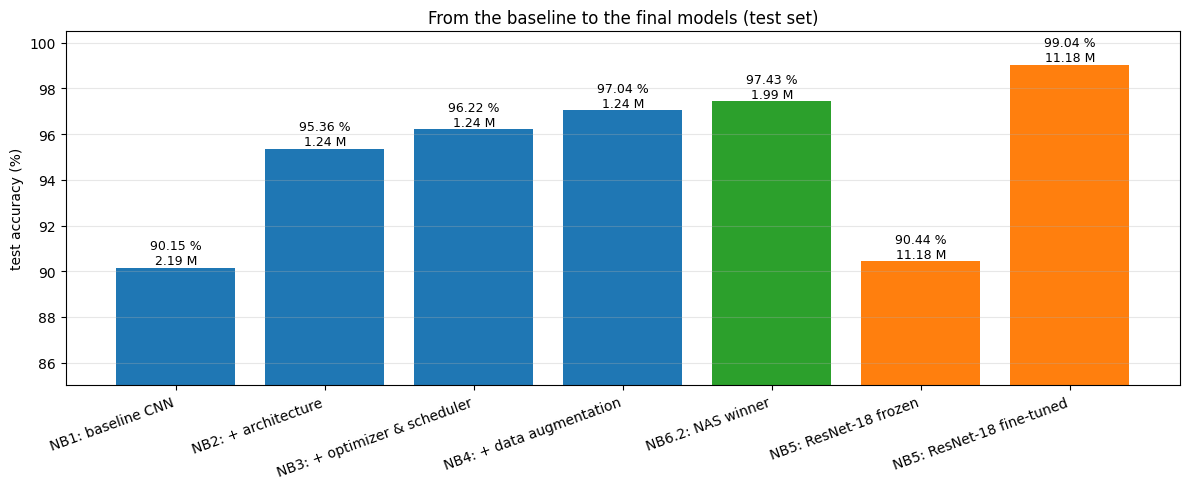

NB1: baseline CNN                NB1_baseline_sgd_lr0.01_bs64_30ep        90.15 %
NB2: + architecture              NB2_combined                             95.36 %
NB3: + optimizer & scheduler     NB3_Adam_lr0.001_StepLR                  96.22 %
NB4: + data augmentation         NB4_flips_crop_mixup                     97.04 %
NB6.2: NAS winner                NB6_2_nas_winner                         97.43 %
NB5: ResNet-18 frozen            NB5_frozen_100pct                        90.44 %
NB5: ResNet-18 fine-tuned        NB5_full_100pct                          99.04 %


In [ ]:
STORY = [
    ("NB1: baseline CNN", "NB1_baseline_sgd_lr0.01_bs64_30ep"),
    ("NB2: + architecture", "NB2_combined"),
    ("NB3: + optimizer & scheduler", "NB3_" + max(nb3["summaries"], key=lambda n: nb3["summaries"][n]["best_val_acc"])),
    ("NB4: + data augmentation", "NB4_" + max(nb4["summaries"], key=lambda n: nb4["summaries"][n]["best_val_acc"])),
    ("NB6.2: NAS winner", "NB6_2_nas_winner"),
    ("NB5: ResNet-18 frozen", "NB5_frozen_100pct"),
    ("NB5: ResNet-18 fine-tuned", "NB5_full_100pct"),
]
fig, ax = plt.subplots(figsize=(12, 5))
accs = [master[ckpt]["test_acc"] for _, ckpt in STORY]
colors = ["tab:blue"] * 4 + ["tab:green"] + ["tab:orange"] * 2
bars = ax.bar(range(len(STORY)), accs, color=colors)
for b, a, (_, ckpt) in zip(bars, accs, STORY):
    ax.text(b.get_x() + b.get_width() / 2, a + 0.15, "%.2f %%\n%.2f M" % (a, master[ckpt]["params"] / 1e6), ha="center", fontsize=9)
ax.set_xticks(range(len(STORY))); ax.set_xticklabels([s for s, _ in STORY], rotation=20, ha="right")
ax.set_ylim(85, 100.5); ax.set_ylabel("test accuracy (%)"); ax.set_title("From the baseline to the final models (test set)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
for label, ckpt in STORY:
    print('%-32s %-40s %.2f %%' % (label, ckpt, master[ckpt]["test_acc"]))

**Accuracy vs cost.** A model is only better if the gain is worth its size and its inference time. The models on the **Pareto front** are those for which no other model is both more accurate and faster.

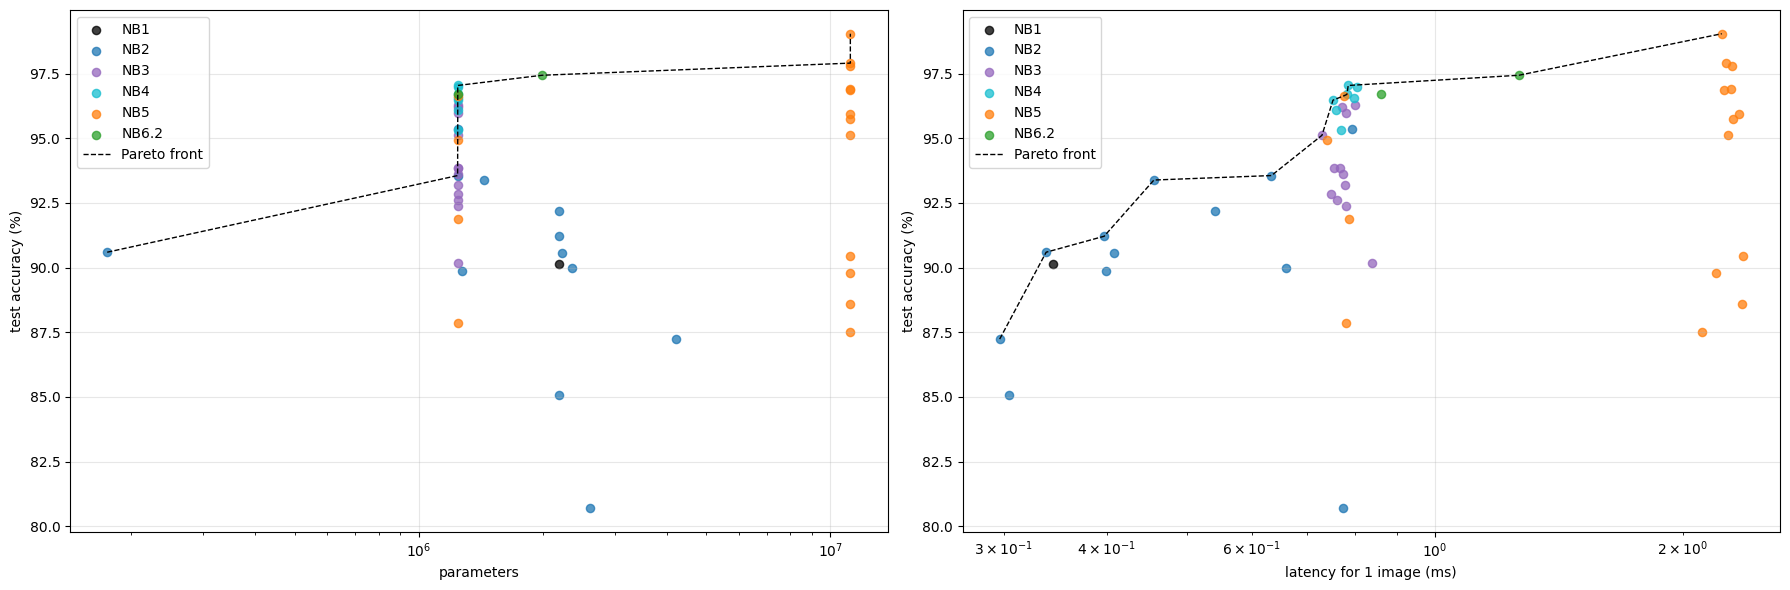

Pareto front (latency): ['NB2_depth_2blocks', 'NB2_fc_1layers', 'NB2_baseline', 'NB2_depth_4blocks', 'NB2_depth_5blocks', 'NB3_Adam_lr0.001', 'NB4_flips_crop_affine', 'NB5_scratch_100pct', 'NB4_flips', 'NB4_flips_crop_mixup', 'NB6_2_nas_winner', 'NB5_full_100pct']


In [ ]:
NB_COLORS = {"NB1": "black", "NB2": "tab:blue", "NB3": "tab:purple", "NB4": "tab:cyan", "NB5": "tab:orange", "NB6.2": "tab:green"}
names = [n for n in master if master[n]["test_acc"] > 80]          # hide the few very bad runs (e.g. 7x7 kernels, 5 % of the data)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, key, label in [(axes[0], "params", "parameters"), (axes[1], "latency_ms", "latency for 1 image (ms)")]:
    for nb_name, color in NB_COLORS.items():
        sel = [n for n in names if master[n]["notebook"] == nb_name]
        ax.scatter([master[n][key] for n in sel], [master[n]["test_acc"] for n in sel], c=color, label=nb_name, alpha=0.75, s=35)
    # Pareto front: sorted by cost, keep a model if it is more accurate than every cheaper model
    front, best = [], 0.0
    for n in sorted(names, key=lambda n: master[n][key]):
        if master[n]["test_acc"] > best:
            front.append(n); best = master[n]["test_acc"]
    ax.plot([master[n][key] for n in front], [master[n]["test_acc"] for n in front], "k--", lw=1, label="Pareto front")
    ax.set_xscale("log"); ax.set_xlabel(label); ax.set_ylabel("test accuracy (%)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()
print("Pareto front (latency):", front)

## e. The 3 finalists face to face

- **hand-designed CNN**: the best NB4 model (our architecture + recipe + augmentation, designed by hand)
- **NAS winner**: the architecture found by zero-cost NAS in NB6.2, same training recipe
- **ResNet-18 fine-tuned**: transfer learning from ImageNet, NB5

model                    test acc   macro-F1     params  latency (ms)     errors
hand-designed CNN          97.04%      96.97    1244202         0.785        120
NAS winner                 97.43%      97.36    1994122         1.265        104
ResNet-18 fine-tuned       99.04%      98.99   11181642         2.229         39


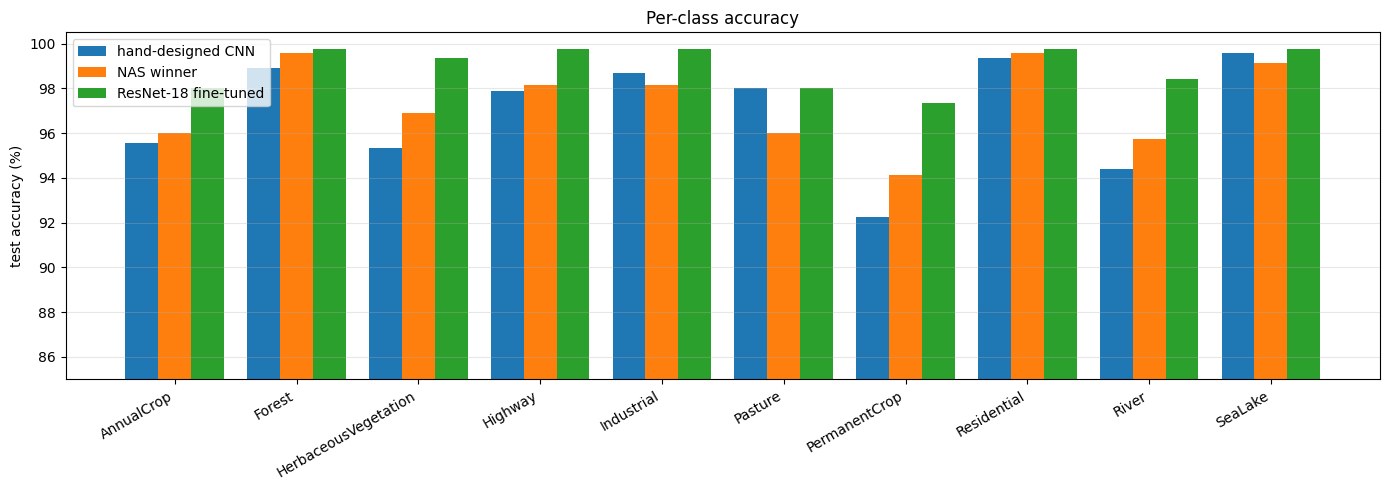

In [ ]:
FINALISTS = {"hand-designed CNN": STORY[3][1], "NAS winner": "NB6_2_nas_winner", "ResNet-18 fine-tuned": "NB5_full_100pct"}
labels_np = np.array(master_labels)

print('%-22s %10s %10s %10s %13s %10s' % ('model', 'test acc', 'macro-F1', 'params', 'latency (ms)', 'errors'))
for label, ckpt in FINALISTS.items():
    r = master[ckpt]
    print('%-22s %9.2f%% %10.2f %10d %13.3f %10d' % (label, r["test_acc"], r["test_f1_macro"], r["params"], r["latency_ms"], (np.array(r["preds"]) != labels_np).sum()))

# per-class accuracy
fig, ax = plt.subplots(figsize=(14, 5))
w = 0.27
for k, (label, ckpt) in enumerate(FINALISTS.items()):
    ax.bar(np.arange(num_classes) + (k - 1) * w, master[ckpt]["per_class_acc"], w, label=label)
ax.set_xticks(range(num_classes)); ax.set_xticklabels(classes, rotation=30, ha="right")
ax.set_ylim(85, 100.5); ax.set_ylabel("test accuracy (%)"); ax.set_title("Per-class accuracy"); ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

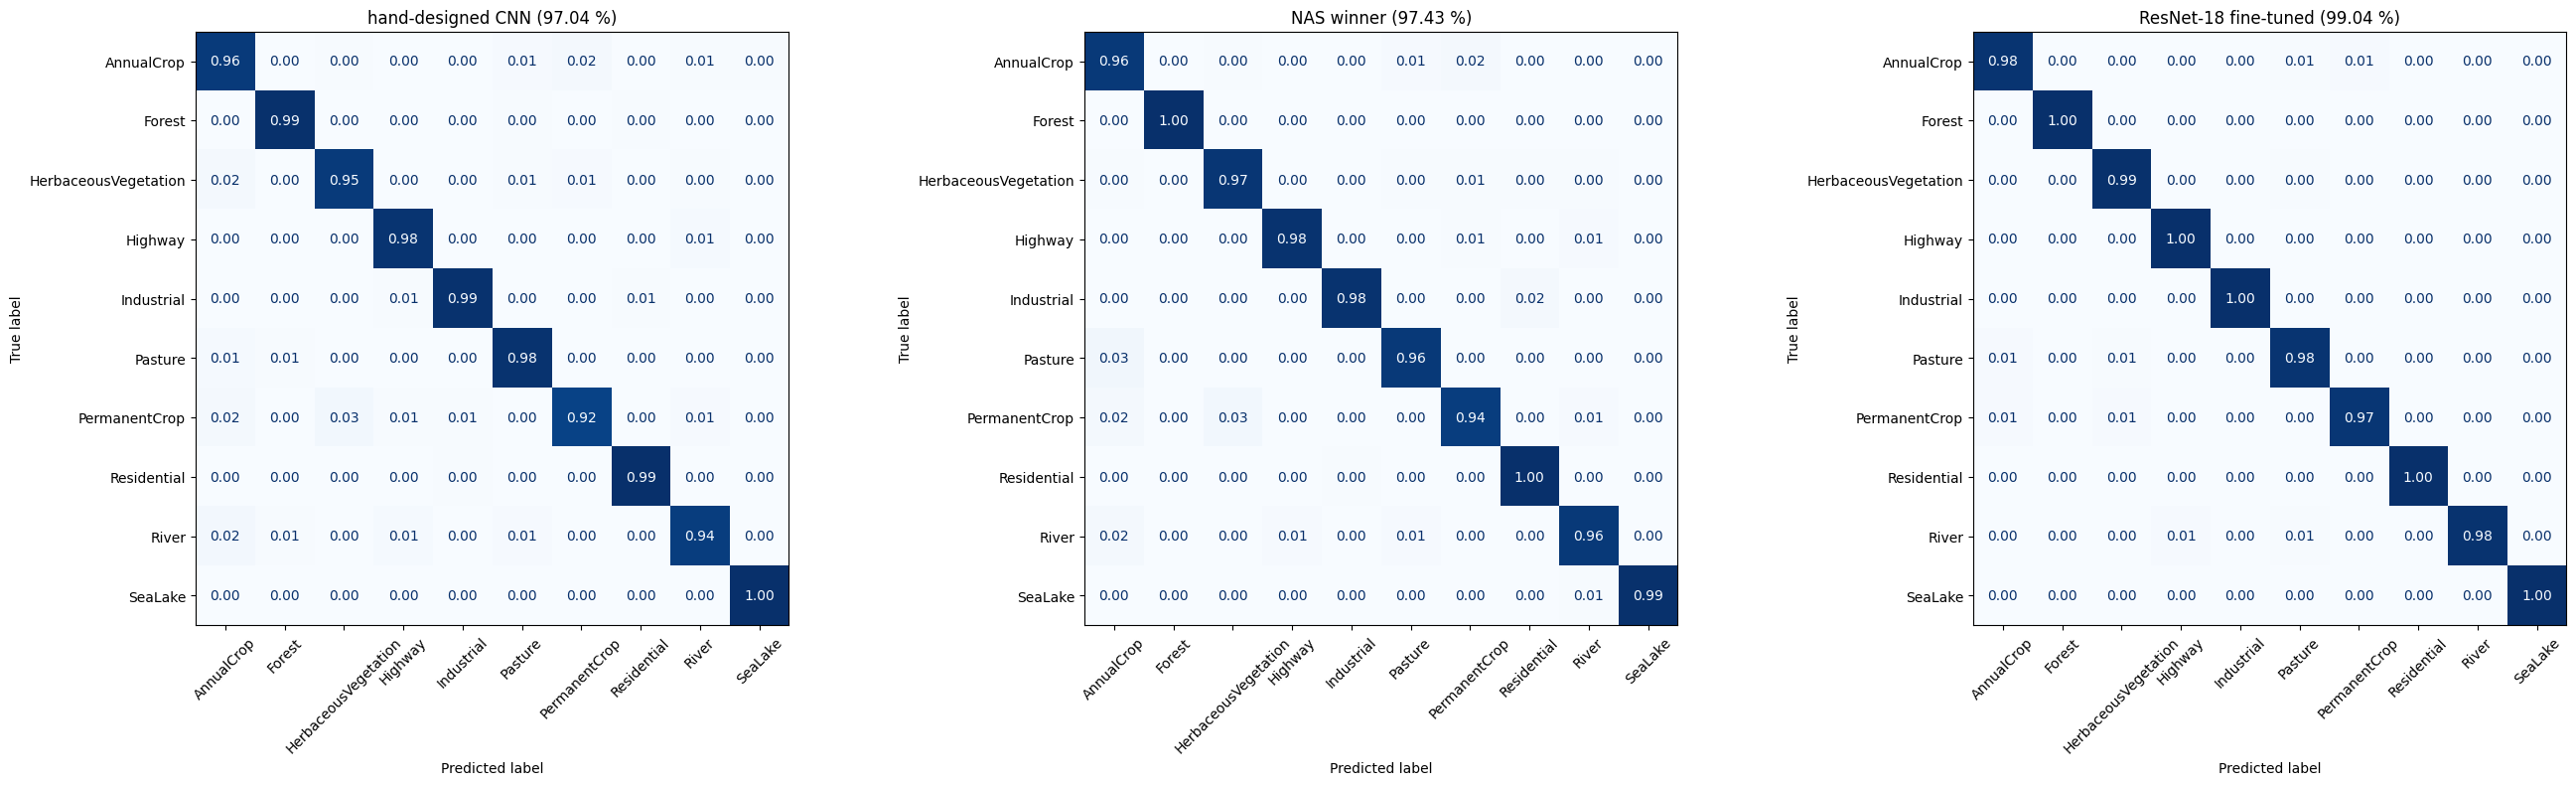

hand-designed CNN      PermanentCrop -> HerbaceousVegetation (11) | River -> AnnualCrop (9) | PermanentCrop -> AnnualCrop (7)
NAS winner             PermanentCrop -> HerbaceousVegetation (11) | Pasture -> AnnualCrop (10) | AnnualCrop -> PermanentCrop (7)
ResNet-18 fine-tuned   AnnualCrop -> PermanentCrop (5) | PermanentCrop -> HerbaceousVegetation (4) | PermanentCrop -> AnnualCrop (4)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(27, 8))
for ax, (label, ckpt) in zip(axes, FINALISTS.items()):
    cm = confusion_matrix(labels_np, master[ckpt]["preds"], normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45, colorbar=False)
    ax.set_title("%s (%.2f %%)" % (label, master[ckpt]["test_acc"]))
plt.tight_layout()
plt.show()

# most confused pairs of each finalist
for label, ckpt in FINALISTS.items():
    cm = confusion_matrix(labels_np, master[ckpt]["preds"])
    np.fill_diagonal(cm, 0)
    worst = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:3], cm.shape))[0]
    print('%-22s' % label, ' | '.join('%s -> %s (%d)' % (classes[i], classes[j], cm[i, j]) for i, j in worst))

**Do the models make the same mistakes?** If two models fail on different images, combining them (ensemble) could help; if they fail on the same images, these images are probably ambiguous (or mislabeled).

hand-designed CNN      & NAS winner            :  72 common errors
hand-designed CNN      & ResNet-18 fine-tuned  :  17 common errors
NAS winner             & ResNet-18 fine-tuned  :  15 common errors
misclassified by all 3 models: 14


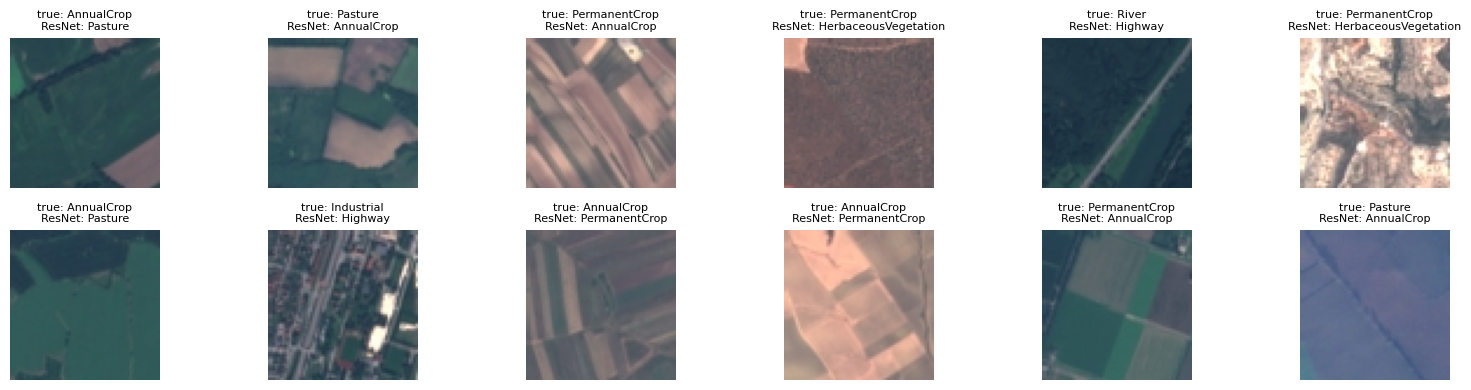

In [ ]:
wrong = {label: set(np.where(np.array(master[ckpt]["preds"]) != labels_np)[0]) for label, ckpt in FINALISTS.items()}
labels_list = list(FINALISTS)
for a in range(3):
    for b in range(a + 1, 3):
        common = wrong[labels_list[a]] & wrong[labels_list[b]]
        print('%-22s & %-22s: %3d common errors' % (labels_list[a], labels_list[b], len(common)))
all_wrong = sorted(wrong[labels_list[0]] & wrong[labels_list[1]] & wrong[labels_list[2]])
print("misclassified by all 3 models:", len(all_wrong))

# the images that all 3 models get wrong
raw_test = Subset(torchvision.datasets.ImageFolder(root=DATA_ROOT), splits["test"])
show = all_wrong[:12]
plt.figure(figsize=(16, 4))
for k, i in enumerate(show):
    img, y = raw_test[i]
    plt.subplot(2, 6, k + 1)
    plt.imshow(img); plt.axis("off")
    plt.title("true: %s\nResNet: %s" % (classes[y], classes[master["NB5_full_100pct"]["preds"][i]]), fontsize=8)
plt.tight_layout()
plt.show()

## f. Defense playground

### f1. Load any checkpoint and test it on unseen mini-batches

Change `NAME` to any checkpoint of the registry (the list is printed below). Everything runs on the CPU.

In [ ]:
print(sorted(REGISTRY.keys()))

['NB1_baseline_sgd_lr0.01_bs64_30ep', 'NB2_baseline', 'NB2_batchnorm', 'NB2_combined', 'NB2_depth_2blocks', 'NB2_depth_4blocks', 'NB2_depth_5blocks', 'NB2_downsample_stride', 'NB2_fc_1layers', 'NB2_fc_3layers', 'NB2_kernel_5x5', 'NB2_kernel_7x7', 'NB2_padding_valid', 'NB3_AdamW_lr0.0001', 'NB3_AdamW_lr0.001', 'NB3_AdamW_lr0.01', 'NB3_Adam_lr0.0001', 'NB3_Adam_lr0.001', 'NB3_Adam_lr0.001_Cosine', 'NB3_Adam_lr0.001_OneCycle', 'NB3_Adam_lr0.001_StepLR', 'NB3_Adam_lr0.01', 'NB3_SGD_lr0.0001', 'NB3_SGD_lr0.001', 'NB3_SGD_lr0.01', 'NB4_flips', 'NB4_flips_crop', 'NB4_flips_crop_affine', 'NB4_flips_crop_affine_jitter', 'NB4_flips_crop_cutmix', 'NB4_flips_crop_mixup', 'NB4_none', 'NB5_frozen_100pct', 'NB5_frozen_10pct', 'NB5_frozen_25pct', 'NB5_frozen_5pct', 'NB5_full_100pct', 'NB5_full_10pct', 'NB5_full_25pct', 'NB5_full_5pct', 'NB5_partial_100pct', 'NB5_partial_10pct', 'NB5_partial_25pct', 'NB5_partial_5pct', 'NB5_scratch_100pct', 'NB5_scratch_10pct', 'NB5_scratch_25pct', 'NB5_scratch_5pct', 

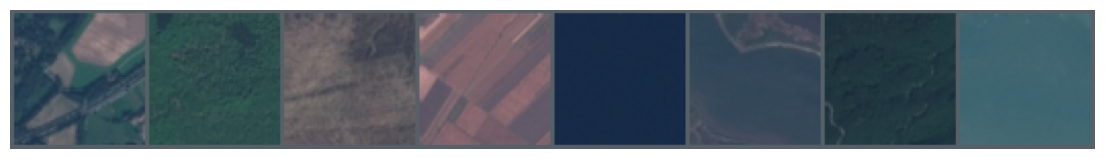

GroundTruth:  Highway | Forest | HerbaceousVegetation | AnnualCrop | SeaLake | SeaLake | Forest | SeaLake
Predicted  :  Highway (0.48) | Forest (0.99) | HerbaceousVegetation (0.98) | AnnualCrop (0.90) | SeaLake (0.98) | SeaLake (0.78) | Forest (0.98) | SeaLake (0.96)


In [ ]:
NAME = "NB6_2_nas_winner"

trainednet, kind = load_model(NAME, map_location="cpu")

def imshow(img, mean, std):
    img = img * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)
    npimg = img.clamp(0, 1).numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")

demo_loader = DataLoader(testsets[kind], batch_size=8, shuffle=True)
images, labels = next(iter(demo_loader))
with torch.no_grad():
    outputs = trainednet(images)
    softmax = nn.Softmax(dim=1)
    probs = softmax(outputs)
    conf, predicted = torch.max(probs, 1)

plt.figure(figsize=(14, 3))
imshow(torchvision.utils.make_grid(images, nrow=8), *((MEAN, STD) if kind == "scratch" else (IMAGENET_MEAN, IMAGENET_STD)))
plt.show()
print('GroundTruth: ', ' | '.join('%s' % classes[labels[j]] for j in range(8)))
print('Predicted  : ', ' | '.join('%s (%.2f)' % (classes[predicted[j]], conf[j]) for j in range(8)))

### f2. Classify one image file

Any 64×64 RGB image works (e.g. a file of the dataset folder). We show the 3 most probable classes.

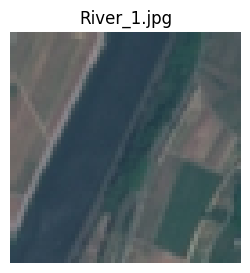

River                  0.990
AnnualCrop             0.003
PermanentCrop          0.003


In [ ]:
from PIL import Image

IMAGE_FILE = os.path.join(DATA_ROOT, "River", sorted(os.listdir(os.path.join(DATA_ROOT, "River")))[0])

img = Image.open(IMAGE_FILE).convert("RGB")
x = EVAL_TRANSFORMS[kind](img).unsqueeze(0)          # [1, 3, H, W]: a batch of 1 image
with torch.no_grad():
    probs = nn.Softmax(dim=1)(trainednet(x))[0]
top_p, top_c = torch.topk(probs, 3)
plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis("off"); plt.title(os.path.basename(IMAGE_FILE)); plt.show()
for p, c in zip(top_p, top_c):
    print('%-22s %.3f' % (classes[c], p))

### f3. Quick live experiments

`quick_experiment` trains a network for a few epochs on **a fraction of the training set**, so that it runs in about a minute on a CPU. Every ingredient can be changed: the network, the augmentation, the optimizer and learning rate, the loss. The numbers are much lower than in the real trainings (little data, few epochs): only the **comparison between two settings** is meaningful.

In [ ]:
def quick_experiment(net, augmentations=[], optimizer_name="Adam", lr=1e-3, criterion=nn.CrossEntropyLoss(),
                     n_epochs=2, train_frac=0.1, mix=None, seed=SEED):
    set_seed(seed)
    run_device = device
    train_transform = transforms.Compose(augmentations + [transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    idx = np.random.RandomState(0).choice(splits["train"], int(train_frac * len(splits["train"])), replace=False)
    trainloader = DataLoader(Subset(torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=train_transform), idx.tolist()),
                             batch_size=64, shuffle=True, num_workers=NUM_WORKERS)
    valloader = DataLoader(Subset(torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=EVAL_TRANSFORMS["scratch"]), splits["val"][:1000]),
                           batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
    net = net.to(run_device)
    if optimizer_name == "SGD":
        optimizer = optim.SGD(net.parameters(), lr=lr, momentum=0.9)
    else:
        optimizer = getattr(optim, optimizer_name)(net.parameters(), lr=lr)
    for epoch in range(n_epochs):
        start = time.time()
        net.train()
        for i, data in enumerate(trainloader, 0):
            inputs, labels = data[0].to(run_device), data[1].to(run_device)
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
        _, val_acc, _, _, _ = evaluate(net, valloader, nn.CrossEntropyLoss())
        print('[epoch %d] last train loss: %.3f | val acc (1000 images): %.2f %% | %.0f s' % (epoch + 1, loss.item(), val_acc, time.time() - start))
    return net


def replace_activation(net, new_activation):
    # replaces every nn.ReLU of the network by another activation module (e.g. nn.LeakyReLU, nn.GELU)
    for name, module in net.named_children():
        if isinstance(module, nn.ReLU):
            setattr(net, name, new_activation())
        else:
            replace_activation(module, new_activation)
    return net

**Reference run**: the hand-designed architecture (NB2), Adam lr 1e-3, no augmentation.

In [ ]:
ref = quick_experiment(ConfigNet(**nb4["arch"]))

[epoch 1] last train loss: 1.439 | val acc (1000 images): 51.70 % | 12 s
[epoch 2] last train loss: 0.697 | val acc (1000 images): 59.50 % | 2 s


**Examples of live modifications** — change one thing, run, compare with the reference:

In [ ]:
# 1. a different learning rate / optimizer
_ = quick_experiment(ConfigNet(**nb4["arch"]), optimizer_name="SGD", lr=1e-2)

[epoch 1] last train loss: 1.349 | val acc (1000 images): 42.90 % | 2 s
[epoch 2] last train loss: 0.786 | val acc (1000 images): 58.90 % | 2 s


In [ ]:
# 2. a different activation function: every ReLU becomes a LeakyReLU
net = replace_activation(ConfigNet(**nb4["arch"]), lambda: nn.LeakyReLU(0.1))
print(net.features[0])
_ = quick_experiment(net)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): LeakyReLU(negative_slope=0.1)
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
[epoch 1] last train loss: 1.512 | val acc (1000 images): 45.70 % | 2 s
[epoch 2] last train loss: 0.586 | val acc (1000 images): 59.00 % | 2 s


In [ ]:
# 3. a different loss: cross-entropy with label smoothing 0.1 (target 0.91 for the true class, 0.01 for each of the 9 others)
_ = quick_experiment(ConfigNet(**nb4["arch"]), criterion=nn.CrossEntropyLoss(label_smoothing=0.1))

[epoch 1] last train loss: 1.677 | val acc (1000 images): 55.70 % | 2 s
[epoch 2] last train loss: 1.058 | val acc (1000 images): 69.60 % | 2 s


In [ ]:
# 4. a different augmentation
_ = quick_experiment(ConfigNet(**nb4["arch"]), augmentations=[transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip()])

[epoch 1] last train loss: 1.364 | val acc (1000 images): 45.00 % | 2 s
[epoch 2] last train loss: 0.698 | val acc (1000 images): 56.80 % | 2 s


In [ ]:
# 5. a different architecture: anything from the NAS search space (NB6.2)
_ = quick_experiment(SearchNet(kernels=[5, 3, 3], width=16, use_bn=True, downsample="stride", skip=True))

[epoch 1] last train loss: 1.628 | val acc (1000 images): 61.30 % | 2 s
[epoch 2] last train loss: 0.738 | val acc (1000 images): 66.70 % | 2 s


In [ ]:
# 6. fine-tune a trained checkpoint for 1 more epoch (start from the NB1 baseline instead of random weights)
net, _ = load_model("NB1_baseline_sgd_lr0.01_bs64_30ep", map_location="cpu")
_ = quick_experiment(net, lr=1e-4, n_epochs=1)

[epoch 1] last train loss: 0.003 | val acc (1000 images): 89.80 % | 2 s
